## 📐 1. Formulasi Matematis Manhattan Distance & Prinsip DBSCAN

### 1.1. Manhattan Distance
Jarak yang digunakan untuk menentukan tetangga:
$$d(x,y)=\sum_{i=1}^{p}|x_i-y_i|.$$

### 1.2. Lingkungan Kepadatan
DBSCAN membentuk lingkungan radius $\varepsilon$:
$$N_\varepsilon(x)=\{y:d(x,y)\leq\varepsilon\}.$$
Titik menjadi **core point** ketika $|N_\varepsilon(x)|\geq\mathrm{min\_samples}$,
dengan titik itu sendiri ikut dihitung. **Border point** berada dalam
jangkauan core point, tetapi tidak memenuhi jumlah minimum tetangga.
Label `-1` menunjukkan **noise**.

Semua baris dan fitur hasil StandardScaler digunakan untuk clustering.
Silhouette memakai seluruh data non-noise dan metrik jarak yang sama,
ketika jumlah klaster memenuhi syarat. PCA diterapkan untuk visualisasi.

In [1]:
# =======================================================================
# 1. SETUP & IMPORT LIBRARY
# =======================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 120

from sklearn.metrics import pairwise_distances

from sklearn.neighbors import NearestNeighbors
from sklearn import config_context


In [2]:
# =======================================================================
# 2. DATASET & PREPROCESSING
# =======================================================================
FILE = 'dataset_B_05_2020 (1).csv'
df = pd.read_csv(FILE)

print('Shape dataset:', df.shape)
print('Jumlah data:', df.shape[0])
print('Jumlah kolom:', df.shape[1])
display(df.head(3))

# Metadata dan label asli disimpan terpisah dari fitur clustering.
urls = df['url'].copy()
y_true = df['status'].copy()
labels = y_true.copy()
X = df.drop(columns=['url', 'status']).select_dtypes(include=np.number)
print('Shape fitur numerik:', X.shape)

# Imputasi median, penghapusan fitur konstan, lalu StandardScaler.
print('Missing value sebelum imputasi:', int(X.isna().sum().sum()))
X = X.fillna(X.median())
print('Missing value setelah imputasi:', int(X.isna().sum().sum()))

selector = VarianceThreshold(threshold=0)
X_sel = selector.fit_transform(X)
selected_features = X.columns[selector.get_support()]
removed_features = X.columns[~selector.get_support()]
X_selected = pd.DataFrame(X_sel, columns=selected_features, index=X.index)
print('Fitur konstan yang dihapus:', list(removed_features))
print('Shape setelah seleksi fitur:', X_selected.shape)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_selected)
df_after = pd.DataFrame(X_scaled, columns=selected_features, index=X.index)
print('Shape setelah StandardScaler:', X_scaled.shape)
display(df_after.head(3))


Shape dataset: (11430, 89)
Jumlah data: 11430
Jumlah kolom: 89


,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,...,0,1,0,45,-1,0,1,1,4,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,77,23,1,1,0,0,0,0,0,...,1,0,0,77,5767,0,0,1,2,phishing
2,https://support-appleld.com.secureupdate.duila...,126,50,1,4,1,0,1,2,0,...,1,0,0,14,4004,5828815,0,1,0,phishing


Shape fitur numerik: (11430, 87)
Missing value sebelum imputasi: 0
Missing value setelah imputasi: 0
Fitur konstan yang dihapus: ['nb_or', 'ratio_nullHyperlinks', 'ratio_intRedirection', 'ratio_intErrors', 'submit_email', 'sfh']
Shape setelah seleksi fitur: (11430, 81)
Shape setelah StandardScaler: (11430, 81)


,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_eq,nb_underscore,...,empty_title,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank
0,-0.436327,-0.193964,-0.421020,0.379116,-0.477984,-0.142915,-0.387464,-0.197604,-0.293683,-0.295128,...,-0.377549,-1.860473,1.129194,-0.28037,-0.549299,-1.307594,-0.429340,6.978227,0.934264,0.320974
1,0.287067,0.177207,2.375182,-1.081136,-0.477984,-0.142915,-0.387464,-0.197604,-0.293683,-0.295128,...,-0.377549,0.537498,-0.885587,-0.28037,-0.510022,0.548471,-0.429340,-0.143303,0.934264,-0.467407
2,1.173224,2.682613,2.375182,1.109242,0.001174,-0.142915,2.356473,2.237556,2.711505,1.534217,...,-0.377549,0.537498,-0.885587,-0.28037,-0.587348,-0.018839,2.491612,-0.143303,0.934264,-1.255788


### Contoh jarak Manhattan dengan library

P0, P1, dan P2 memakai seluruh fitur input model. Jarak dihitung dengan
`pairwise_distances(metric="manhattan")`. Buka **Rincian fitur** untuk melihat P0–P1.

Jarak per fitur dihitung dengan `paired_manhattan_distances`. Jumlah kontribusi fitur sama dengan jarak Manhattan keseluruhan.


In [3]:
from IPython.display import HTML
from sklearn.metrics.pairwise import paired_manhattan_distances

EXAMPLE_NODES = [0, 1, 2]
EXAMPLE_METRIC = 'manhattan'
EXAMPLE_DATA = X_scaled

def tampilkan_fitur(x, y, nama_x, nama_y):
    feature_df = pd.DataFrame({'Fitur': selected_features, nama_x: x, nama_y: y})
    per_feature = paired_manhattan_distances(x[:, None], y[:, None])
    feature_df['Kontribusi jarak (builtin)'] = per_feature
    print(f'Jumlah kontribusi fitur: {per_feature.sum():.8f}')

    distance = pairwise_distances(x[None, :], y[None, :], metric=EXAMPLE_METRIC)[0, 0]
    print(f'{nama_x} -> {nama_y}: jarak {EXAMPLE_METRIC} builtin = {distance:.8f}')
    table = feature_df.to_html(index=False, float_format=lambda value: f'{value:.8f}')
    display(HTML(f'<details><summary>Rincian {len(feature_df)} fitur: {nama_x} ke {nama_y}</summary>'
                 f'<div style="overflow-x:auto">{table}</div></details>'))
    return feature_df

pair_rows = []
for a, b in [(0, 1), (0, 2), (1, 2)]:
    distance = pairwise_distances(EXAMPLE_DATA[a:a + 1], EXAMPLE_DATA[b:b + 1], metric=EXAMPLE_METRIC)[0, 0]
    pair_rows.append({'Pasangan': f'P{a} - P{b}', 'Jarak builtin': distance})
pair_distance_df = pd.DataFrame(pair_rows)
display(pair_distance_df.round(8))
feature_pair_df = tampilkan_fitur(EXAMPLE_DATA[0], EXAMPLE_DATA[1], 'P0', 'P1')


,Pasangan,Jarak builtin
0,P0 - P1,58.498862
1,P0 - P2,73.599151
2,P1 - P2,52.856607


Jumlah kontribusi fitur: 58.49886247
P0 -> P1: jarak manhattan builtin = 58.49886247


Fitur,P0,P1,Kontribusi jarak (builtin)
length_url,-0.43632748,0.28706655,0.72339403
length_hostname,-0.19396372,0.17720743,0.37117115
ip,-0.42102044,2.37518157,2.79620202
nb_dots,0.37911625,-1.08113606,1.46025231
nb_hyphens,-0.47798396,-0.47798396,0.00000000
nb_at,-0.14291457,-0.14291457,0.00000000
nb_qm,-0.38746409,-0.38746409,0.00000000
nb_and,-0.19760370,-0.19760370,0.00000000
nb_eq,-0.29368288,-0.29368288,0.00000000
nb_underscore,-0.29512783,-0.29512783,0.00000000


## 📈 2. Parameter DBSCAN dan K-Distance Plot

Seluruh metrik memakai `EPS = 0.5`, `MIN_SAMPLES = 5`, `algorithm="brute"`, dan `n_jobs=1`.
K-Distance Plot menunjukkan kandidat eps untuk belajar; parameter fit tetap sama.


In [4]:
# =======================================================================
# 3. PARAMETER DBSCAN
# =======================================================================
DISTANCE_METRIC = 'manhattan'
EPS = 0.5
MIN_SAMPLES = 5
print('Metrik jarak:', DISTANCE_METRIC)
print('EPS:', EPS)
print('MIN_SAMPLES:', MIN_SAMPLES)


Metrik jarak: manhattan
EPS: 0.5
MIN_SAMPLES: 5


### K-Distance Plot untuk membaca kandidat `eps`

Dengan `MIN_SAMPLES = 5`, sebuah core point perlu lima anggota lingkungan,
**termasuk dirinya sendiri**. `kneighbors(X_scaled)` memasukkan jarak nol
ke titik query; kolom terakhir dari lima jarak terdekat adalah jarak ke
tetangga keempat selain dirinya (duplikat juga dihitung sebagai baris).
Jarak tersebut dihitung untuk setiap node, diurutkan menaik, lalu diplot.

Siku kurva memberikan **kandidat** `eps`, bukan jaminan parameter optimal.
Penanda memakai jarak terbesar antara kurva yang dinormalisasi dan garis
penghubung kedua ujung; kurva datar tidak diberi kandidat. Periksa bentuk
kurva dan hasil klaster sebelum memakai kandidat tersebut.

Untuk studi perbandingan ini, **`EPS = 0.5` tetap digunakan pada semua
metrik**, bersama `MIN_SAMPLES`, `algorithm`, dan `n_jobs` yang sama.
Kandidat dari plot tidak mengganti parameter fit. Nilai numerik `eps`
yang sama mempunyai skala/geometri berbeda pada Euclidean, Manhattan,
dan Cosine, sehingga ini membandingkan perilaku dengan parameter tetap.

Jarak ke titik sendiri dapat tampil sebagai angka sangat kecil karena
presisi floating point; secara matematis nilainya nol.

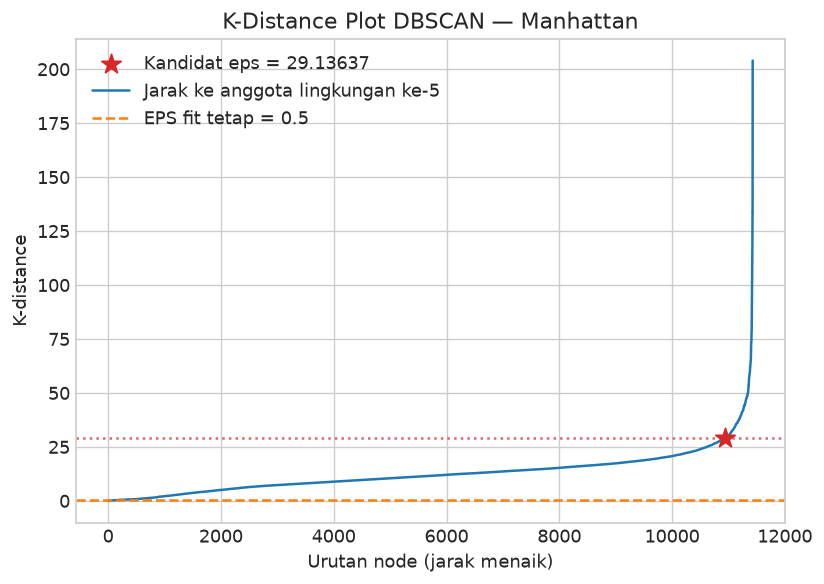

,Metrik,MIN_SAMPLES (termasuk sendiri),k (selain sendiri),Kandidat eps (heuristik),EPS untuk fit
0,manhattan,5,4,29.136368,0.5


Contoh urutan tetangga P0, P1, P2; jarak terakhir menjadi nilai K-distance node tersebut.
Pada jarak seri/duplikat, ID tetangga yang dipilih dapat berbeda; nilai jaraknya tetap sama.


,Metrik,Node query,Urutan,Node tetangga,Jarak,Dalam EPS
0,manhattan,P0,1,P0,0.000000,True
1,manhattan,P0,2,P9333,19.582308,False
2,manhattan,P0,3,P4886,20.192799,False
3,manhattan,P0,4,P5912,21.543182,False
4,manhattan,P0,5,P2098,22.176390,False
5,manhattan,P1,1,P1,0.000000,True
6,manhattan,P1,2,P1651,0.146563,True
7,manhattan,P1,3,P766,0.210927,True
8,manhattan,P1,4,P3406,0.451820,True
9,manhattan,P1,5,P289,0.564735,False


In [5]:
# Semua node digunakan; blok query membatasi memori matriks jarak sementara.
plot_metrics = DISTANCE_METRICS if 'DISTANCE_METRICS' in globals() else [DISTANCE_METRIC]
k_distance_by_metric = {}
knee_eps_by_metric = {}
neighbor_examples = []
fig, axes = plt.subplots(1, len(plot_metrics), figsize=(7 * len(plot_metrics), 5), squeeze=False)
for ax, metric in zip(axes.ravel(), plot_metrics):
    nn = NearestNeighbors(n_neighbors=MIN_SAMPLES, metric=metric,
                          algorithm='brute', n_jobs=1).fit(X_scaled)
    # X diberikan secara eksplisit: hitungan mencakup jarak nol ke titik sendiri.
    with config_context(working_memory=128):
        distances, indices = nn.kneighbors(X_scaled)
    k_distances = np.sort(distances[:, -1])
    k_distance_by_metric[metric] = k_distances
    rank = np.arange(len(k_distances))
    candidate = np.nan
    if np.ptp(k_distances) > 0:
        x_norm = rank / (len(rank) - 1)
        y_norm = (k_distances - k_distances[0]) / np.ptp(k_distances)
        gap = x_norm - y_norm
        knee_index = int(np.argmax(gap))
        if 0 < knee_index < len(rank) - 1 and gap[knee_index] > 1e-6:
            candidate = float(k_distances[knee_index])
            ax.scatter(knee_index, candidate, color='tab:red', marker='*', s=150,
                       zorder=3, label=f'Kandidat eps = {candidate:.5f}')
            ax.axhline(candidate, color='tab:red', ls=':', alpha=0.7)
    knee_eps_by_metric[metric] = candidate
    ax.plot(rank, k_distances, label=f'Jarak ke anggota lingkungan ke-{MIN_SAMPLES}')
    ax.axhline(EPS, color='tab:orange', ls='--', label=f'EPS fit tetap = {EPS}')
    ax.set(xlabel='Urutan node (jarak menaik)', ylabel='K-distance',
           title=f'K-Distance Plot DBSCAN — {metric.title()}')
    ax.legend()
    for node in EXAMPLE_NODES:
        for j in range(MIN_SAMPLES):
            neighbor_examples.append({'Metrik': metric, 'Node query': f'P{node}',
                'Urutan': j + 1, 'Node tetangga': f'P{indices[node, j]}',
                'Jarak': distances[node, j], 'Dalam EPS': distances[node, j] <= EPS})
    del nn, distances, indices
plt.tight_layout()
plt.show()
display(pd.DataFrame([{'Metrik': m, 'MIN_SAMPLES (termasuk sendiri)': MIN_SAMPLES,
    'k (selain sendiri)': MIN_SAMPLES - 1,
    'Kandidat eps (heuristik)': knee_eps_by_metric[m], 'EPS untuk fit': EPS}
    for m in plot_metrics]).round(6))
print('Contoh urutan tetangga P0, P1, P2; jarak terakhir menjadi nilai K-distance node tersebut.')
print('Pada jarak seri/duplikat, ID tetangga yang dipilih dapat berbeda; nilai jaraknya tetap sama.')
display(pd.DataFrame(neighbor_examples).round(8))


In [6]:
# =======================================================================
# 4. EKSEKUSI CLUSTERING DBSCAN
# =======================================================================
dbscan = DBSCAN(
    eps=EPS,
    min_samples=MIN_SAMPLES,
    metric=DISTANCE_METRIC,
    algorithm="brute",
    n_jobs=1
)

cluster_labels = dbscan.fit_predict(X_scaled)

print("Jumlah label cluster:", len(cluster_labels))


Jumlah label cluster: 11430


In [7]:
# =======================================================================
# 5. HASIL KLASTER, NOISE, & METRIK EVALUASI
# =======================================================================
noise_mask = cluster_labels == -1
core_mask = np.zeros(len(cluster_labels), dtype=bool)
core_mask[dbscan.core_sample_indices_] = True
border_mask = (~noise_mask) & (~core_mask)

n_clusters = len(set(cluster_labels)) - int(noise_mask.any())
n_noise = int(noise_mask.sum())

print("Metrik jarak:", DISTANCE_METRIC)
print("Jumlah cluster (tanpa noise):", n_clusters)
print("Jumlah core point:", int(core_mask.sum()))
print("Jumlah border point:", int(border_mask.sum()))
print("Jumlah noise:", n_noise)
print(f"Persentase noise: {100 * noise_mask.mean():.2f}%")

cluster_counts = (
    pd.Series(cluster_labels, name="Cluster")
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Jumlah Data")
)

cluster_counts["Persentase (%)"] = (
    cluster_counts["Jumlah Data"] / len(cluster_labels) * 100
).round(2)

display(cluster_counts)

X_evaluation = X_scaled[~noise_mask]
labels_evaluation = cluster_labels[~noise_mask]
n_evaluation_clusters = len(np.unique(labels_evaluation))

silhouette = None

if 2 <= n_evaluation_clusters < len(labels_evaluation):
    silhouette = silhouette_score(
        X_evaluation,
        labels_evaluation,
        metric=DISTANCE_METRIC
    )
    print("Jumlah data evaluasi (seluruh data non-noise):", len(labels_evaluation))
    print("Jumlah cluster pada data evaluasi:", n_evaluation_clusters)
    print(f"Silhouette score ({DISTANCE_METRIC}): {silhouette:.4f}")
else:
    print("Silhouette tidak dihitung: data evaluasi tidak memenuhi syarat jumlah cluster.")

eval_df = pd.DataFrame([{
    'Distance Metric': DISTANCE_METRIC.title(),
    'EPS': EPS,
    'MIN_SAMPLES': MIN_SAMPLES,
    'Jumlah Klaster': n_clusters,
    'Core Point': int(core_mask.sum()),
    'Border Point': int(border_mask.sum()),
    'Noise': n_noise,
    'Noise (%)': 100 * noise_mask.mean(),
    'Silhouette Score': silhouette if silhouette is not None else np.nan,
}])
display(eval_df.round(4))


Metrik jarak: manhattan
Jumlah cluster (tanpa noise): 30
Jumlah core point: 277
Jumlah border point: 79
Jumlah noise: 11074
Persentase noise: 96.89%


,Cluster,Jumlah Data,Persentase (%)
0,-1,11074,96.89
1,0,15,0.13
2,1,12,0.10
3,2,33,0.29
4,3,12,0.10
5,4,20,0.17
6,5,36,0.31
7,6,17,0.15
8,7,18,0.16
9,8,10,0.09


Jumlah data evaluasi (seluruh data non-noise): 356
Jumlah cluster pada data evaluasi: 30
Silhouette score (manhattan): 0.8311


,Distance Metric,EPS,MIN_SAMPLES,Jumlah Klaster,Core Point,Border Point,Noise,Noise (%),Silhouette Score
0,Manhattan,0.5,5,30,277,79,11074,96.8854,0.8311


### Lingkungan node contoh

Library menghitung jarak ke seluruh dataset. Tetangga memenuhi `jarak <= EPS`,
termasuk node itu sendiri. Core point memiliki sedikitnya `MIN_SAMPLES` tetangga.


In [8]:
example_distances = pairwise_distances(X_scaled[EXAMPLE_NODES], X_scaled, metric=DISTANCE_METRIC)
node_rows = []
for row, node in enumerate(EXAMPLE_NODES):
    example_distances[row, node] = 0.0
    count = int((example_distances[row] <= EPS).sum())
    kind = 'core' if core_mask[node] else ('noise' if cluster_labels[node] == -1 else 'border')
    node_rows.append({'Node': f'P{node}', 'Tetangga dalam EPS (termasuk sendiri)': count,
        'MIN_SAMPLES': MIN_SAMPLES, 'Tipe': kind, 'Label hasil fit': int(cluster_labels[node])})
node_summary_df = pd.DataFrame(node_rows)
display(node_summary_df)


,Node,Tetangga dalam EPS (termasuk sendiri),MIN_SAMPLES,Tipe,Label hasil fit
0,P0,1,5,noise,-1
1,P1,4,5,border,5
2,P2,4,5,border,7


Total explained variance PCA: 15.51%


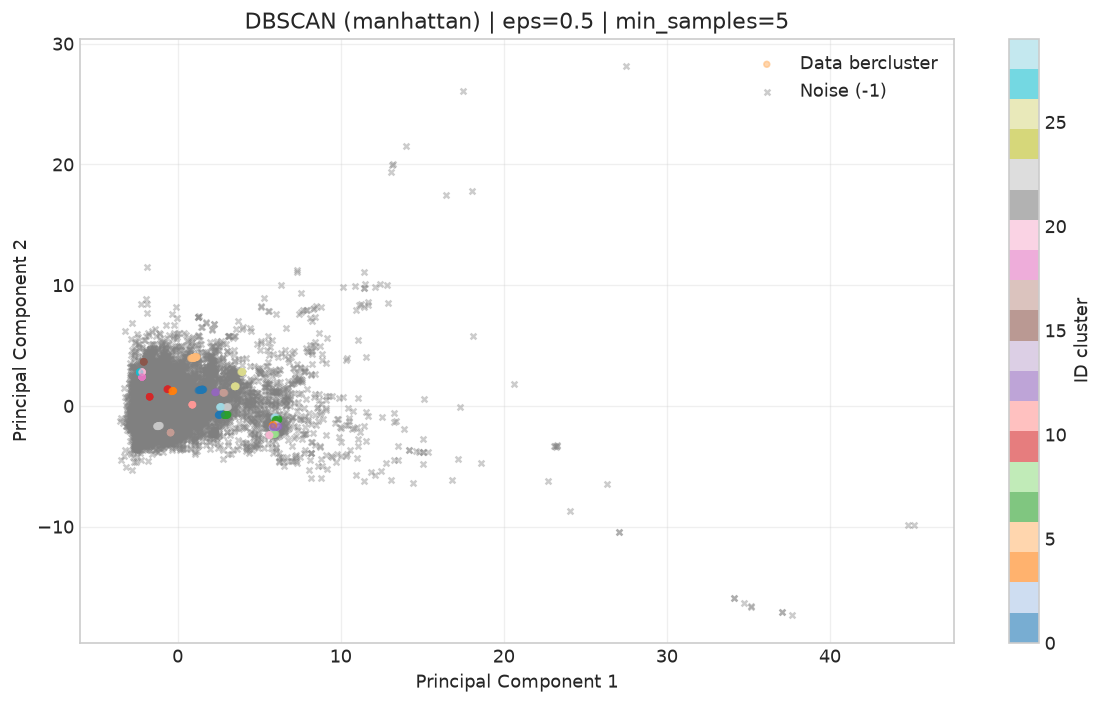

In [9]:
# =======================================================================
# 6. VISUALISASI PCA 2D PEMETAAN KLASTER & NOISE
# =======================================================================
pca = PCA(n_components=2, svd_solver="full", random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

print(f"Total explained variance PCA: {pca.explained_variance_ratio_.sum():.2%}")

fig, ax = plt.subplots(figsize=(10, 6))

if (~noise_mask).any():
    points = ax.scatter(
        X_pca[~noise_mask, 0],
        X_pca[~noise_mask, 1],
        c=cluster_labels[~noise_mask],
        cmap="tab20",
        s=12,
        alpha=0.6,
        zorder=2,
        label="Data bercluster"
    )
    if n_clusters > 1:
        fig.colorbar(
            points,
            ax=ax,
            label="ID cluster",
            ticks=np.unique(cluster_labels[~noise_mask]) if n_clusters <= 10 else None
        )

if noise_mask.any():
    ax.scatter(
        X_pca[noise_mask, 0],
        X_pca[noise_mask, 1],
        c="gray",
        marker="x",
        s=12,
        alpha=0.4,
        zorder=1,
        label="Noise (-1)"
    )

ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.set_title(
    f"DBSCAN ({DISTANCE_METRIC}) | eps={EPS} | min_samples={MIN_SAMPLES}"
)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()
